# 🎓 Student Marks Analysis and Prediction using Apache Spark
**Dataset:** `dataset_synthetic.csv` (department, year, subject, difficulty, internal marks, attendance, study hours, days before exam, end-sem marks)

**Prediction target:** `end_sem_marks` (out of 50)
**Features removed from prediction:** `study_hrs_day` and `attendance_pct` (see the configuration cell in the prediction section)

In [1]:
!pip install -q pyspark

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

In [3]:
spark = SparkSession.builder \
    .appName("StudentMarksAnalysis") \
    .getOrCreate()

print("Spark Session Created Successfully!")
print("Spark Version:", spark.version)

Spark Session Created Successfully!
Spark Version: 4.0.4


## 1. Load the dataset

In [4]:
# In Google Colab this opens an upload box; elsewhere it reads the file from the current folder.
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
except ImportError:
    file_name = "dataset_synthetic.csv"

print("Using file:", file_name)

Saving Student_Marks.csv to Student_Marks.csv
Using file: Student_Marks.csv


In [5]:
df = spark.read.csv(
    file_name,
    header=True,
    inferSchema=True
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.show(10, truncate=False)

+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+
|student_id|department|year|subject             |difficulty|internal_marks|attendance_pct|study_hrs_day|days_before_exam|end_sem_marks|
+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+
|1         |MECH      |3   |Maths I             |1         |43.2          |71.9          |6.9          |5               |38.7         |
|2         |IT        |2   |Maths II            |2         |43.6          |56.4          |3.9          |55              |37.2         |
|3         |CSE       |1   |Maths I             |3         |33.3          |61.4          |4.7          |49              |30.2         |
|4         |MECH      |2   |Data Structures     |3         |30.6          |98.5          |7.2          |11              |32.8         |
|5         |CIVIL     |1   |Software Engineering

In [7]:
print("Column Names:")
print(df.columns)

print("Dataset Schema:")
df.printSchema()

Column Names:
['student_id', 'department', 'year', 'subject', 'difficulty', 'internal_marks', 'attendance_pct', 'study_hrs_day', 'days_before_exam', 'end_sem_marks']
Dataset Schema:
root
 |-- student_id: integer (nullable = true)
 |-- department: string (nullable = true)
 |-- year: integer (nullable = true)
 |-- subject: string (nullable = true)
 |-- difficulty: integer (nullable = true)
 |-- internal_marks: double (nullable = true)
 |-- attendance_pct: double (nullable = true)
 |-- study_hrs_day: double (nullable = true)
 |-- days_before_exam: integer (nullable = true)
 |-- end_sem_marks: double (nullable = true)



In [8]:
print("Total Students:", df.count())
print("Total Columns:", len(df.columns))

Total Students: 300
Total Columns: 10


## 2. Clean the data

In [9]:
df.select([
    F.count(
        F.when(F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == ""), c)
    ).alias(c)
    for c in df.columns
]).show()

+----------+----------+----+-------+----------+--------------+--------------+-------------+----------------+-------------+
|student_id|department|year|subject|difficulty|internal_marks|attendance_pct|study_hrs_day|days_before_exam|end_sem_marks|
+----------+----------+----+-------+----------+--------------+--------------+-------------+----------------+-------------+
|         0|         0|   0|      0|         0|             0|             0|            0|               0|            0|
+----------+----------+----+-------+----------+--------------+--------------+-------------+----------------+-------------+



In [10]:
df_clean = df.dropna().dropDuplicates(["student_id"])

print("Rows before cleaning:", df.count())
print("Rows after cleaning:", df_clean.count())

df_clean.show(5)

Rows before cleaning: 300
Rows after cleaning: 300
+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+
|student_id|department|year|             subject|difficulty|internal_marks|attendance_pct|study_hrs_day|days_before_exam|end_sem_marks|
+----------+----------+----+--------------------+----------+--------------+--------------+-------------+----------------+-------------+
|         1|      MECH|   3|             Maths I|         1|          43.2|          71.9|          6.9|               5|         38.7|
|         2|        IT|   2|            Maths II|         2|          43.6|          56.4|          3.9|              55|         37.2|
|         3|       CSE|   1|             Maths I|         3|          33.3|          61.4|          4.7|              49|         30.2|
|         4|      MECH|   2|     Data Structures|         3|          30.6|          98.5|          7.2|              11|         32.

## 3. Derived columns

In [11]:
# Both exams are out of 50 marks
df_analysis = df_clean.withColumn(
    "total_marks", F.round(F.col("internal_marks") + F.col("end_sem_marks"), 1)   # out of 100
)

# End-sem marks as a percentage (out of 50 -> out of 100)
df_analysis = df_analysis.withColumn(
    "end_sem_pct", F.round(F.col("end_sem_marks") * 2, 1)
)

df_analysis.select(
    "student_id", "department", "subject",
    "internal_marks", "end_sem_marks", "total_marks", "end_sem_pct"
).show(10)

+----------+----------+--------------------+--------------+-------------+-----------+-----------+
|student_id|department|             subject|internal_marks|end_sem_marks|total_marks|end_sem_pct|
+----------+----------+--------------------+--------------+-------------+-----------+-----------+
|         1|      MECH|             Maths I|          43.2|         38.7|       81.9|       77.4|
|         2|        IT|            Maths II|          43.6|         37.2|       80.8|       74.4|
|         3|       CSE|             Maths I|          33.3|         30.2|       63.5|       60.4|
|         4|      MECH|     Data Structures|          30.6|         32.8|       63.4|       65.6|
|         5|     CIVIL|Software Engineering|          24.6|         30.3|       54.9|       60.6|
|         6|        IT|            Maths II|          25.7|         33.8|       59.5|       67.6|
|         7|     CIVIL|  Python Programming|          41.0|         39.7|       80.7|       79.4|
|         8|      ME

In [12]:
# Performance category based on end-sem percentage
df_analysis = df_analysis.withColumn(
    "classification",
    F.when(F.col("end_sem_pct") >= 75, "Distinction")
     .when(F.col("end_sem_pct") >= 60, "First Class")
     .when(F.col("end_sem_pct") >= 40, "Pass")
     .otherwise("At Risk")
)

df_analysis.select("end_sem_marks", "end_sem_pct", "classification").show(10)
df_analysis.groupBy("classification").count().show()

+-------------+-----------+--------------+
|end_sem_marks|end_sem_pct|classification|
+-------------+-----------+--------------+
|         43.9|       87.8|   Distinction|
|         44.7|       89.4|   Distinction|
|         27.4|       54.8|          Pass|
|         23.1|       46.2|          Pass|
|         50.0|      100.0|   Distinction|
|         30.2|       60.4|   First Class|
|         28.1|       56.2|          Pass|
|         43.2|       86.4|   Distinction|
|         27.4|       54.8|          Pass|
|         27.1|       54.2|          Pass|
+-------------+-----------+--------------+
only showing top 10 rows
+--------------+-----+
|classification|count|
+--------------+-----+
|   First Class|  118|
|       At Risk|    4|
|   Distinction|   92|
|          Pass|   86|
+--------------+-----+



In [13]:
# Pass / Fail: a student passes the end-sem with at least 40% (20 out of 50)
df_analysis = df_analysis.withColumn(
    "result",
    F.when(F.col("end_sem_marks") >= 20, "Pass").otherwise("Fail")
)

df_analysis.groupBy("result").count().show()

+------+-----+
|result|count|
+------+-----+
|  Fail|    4|
|  Pass|  296|
+------+-----+



## 4. Analysis

In [14]:
df_analysis.select(
    F.count("*").alias("Total Students"),
    F.round(F.avg("internal_marks"), 2).alias("Avg Internal (/50)"),
    F.round(F.avg("end_sem_marks"), 2).alias("Avg End-Sem (/50)"),
    F.round(F.avg("total_marks"), 2).alias("Avg Total (/100)")
).show()

+--------------+------------------+-----------------+----------------+
|Total Students|Avg Internal (/50)|Avg End-Sem (/50)|Avg Total (/100)|
+--------------+------------------+-----------------+----------------+
|           300|             35.71|            33.89|            69.6|
+--------------+------------------+-----------------+----------------+



In [15]:
department_summary = df_analysis.groupBy("department").agg(
    F.count("*").alias("Number of Students"),
    F.round(F.avg("internal_marks"), 2).alias("Avg Internal"),
    F.round(F.avg("end_sem_marks"), 2).alias("Avg End-Sem"),
    F.round(F.avg("total_marks"), 2).alias("Avg Total")
).orderBy(F.desc("Avg End-Sem"))

department_summary.show(truncate=False)

+----------+------------------+------------+-----------+---------+
|department|Number of Students|Avg Internal|Avg End-Sem|Avg Total|
+----------+------------------+------------+-----------+---------+
|IT        |63                |36.34       |34.53      |70.87    |
|ECE       |62                |35.99       |34.22      |70.21    |
|CIVIL     |76                |36.89       |34.02      |70.91    |
|MECH      |48                |33.69       |33.3       |66.98    |
|CSE       |51                |34.73       |33.07      |67.8     |
+----------+------------------+------------+-----------+---------+



In [16]:
year_summary = df_analysis.groupBy("year").agg(
    F.count("*").alias("Number of Students"),
    F.round(F.avg("end_sem_marks"), 2).alias("Avg End-Sem")
).orderBy("year")

year_summary.show(truncate=False)

+----+------------------+-----------+
|year|Number of Students|Avg End-Sem|
+----+------------------+-----------+
|1   |79                |33.38      |
|2   |76                |33.67      |
|3   |77                |34.22      |
|4   |68                |34.35      |
+----+------------------+-----------+



In [17]:
subject_summary = df_analysis.groupBy("subject").agg(
    F.count("*").alias("Number of Students"),
    F.round(F.avg("end_sem_marks"), 2).alias("Avg End-Sem")
).orderBy(F.desc("Avg End-Sem"))

subject_summary.show(20, truncate=False)

+--------------------+------------------+-----------+
|subject             |Number of Students|Avg End-Sem|
+--------------------+------------------+-----------+
|OOP Java            |16                |37.13      |
|Python Programming  |16                |36.06      |
|Computer Networks   |21                |35.76      |
|DAA                 |28                |35.6       |
|Software Engineering|32                |35.03      |
|Maths I             |27                |34.7       |
|Physics             |16                |34.25      |
|Discrete Mathematics|20                |34.2       |
|DBMS                |25                |32.32      |
|Operating Systems   |29                |32.28      |
|Web Technologies    |17                |32.28      |
|Maths II            |20                |32.07      |
|C Programming       |11                |31.46      |
|Data Structures     |22                |30.86      |
+--------------------+------------------+-----------+



In [18]:
difficulty_summary = df_analysis.groupBy("difficulty").agg(
    F.count("*").alias("Number of Students"),
    F.round(F.avg("internal_marks"), 2).alias("Avg Internal"),
    F.round(F.avg("end_sem_marks"), 2).alias("Avg End-Sem")
).orderBy("difficulty")

difficulty_summary.show(truncate=False)

+----------+------------------+------------+-----------+
|difficulty|Number of Students|Avg Internal|Avg End-Sem|
+----------+------------------+------------+-----------+
|1         |124               |35.61       |37.06      |
|2         |90                |35.61       |33.12      |
|3         |86                |35.96       |30.13      |
+----------+------------------+------------+-----------+



In [19]:
# How strongly is each numeric column related to end-sem marks? (Pearson correlation)
numeric_cols = ["year", "difficulty", "internal_marks", "attendance_pct",
                "study_hrs_day", "days_before_exam"]

corr_rows = [(c, round(df_analysis.stat.corr(c, "end_sem_marks"), 3)) for c in numeric_cols]
correlation_summary = spark.createDataFrame(corr_rows, ["Column", "Correlation with end_sem_marks"])
correlation_summary.orderBy(F.desc(F.abs(F.col("Correlation with end_sem_marks")))).show(truncate=False)

+----------------+------------------------------+
|Column          |Correlation with end_sem_marks|
+----------------+------------------------------+
|internal_marks  |0.594                         |
|study_hrs_day   |0.466                         |
|difficulty      |-0.42                         |
|days_before_exam|0.234                         |
|attendance_pct  |0.199                         |
|year            |0.056                         |
+----------------+------------------------------+



In [20]:
top_students = df_analysis.orderBy(F.desc("total_marks")).select(
    "student_id", "department", "year", "subject",
    "internal_marks", "end_sem_marks", "total_marks", "classification"
)

top_students.show(10, truncate=False)

+----------+----------+----+--------------------+--------------+-------------+-----------+--------------+
|student_id|department|year|subject             |internal_marks|end_sem_marks|total_marks|classification|
+----------+----------+----+--------------------+--------------+-------------+-----------+--------------+
|97        |IT        |2   |DBMS                |49.9          |50.0         |99.9       |Distinction   |
|162       |CSE       |2   |DAA                 |49.8          |50.0         |99.8       |Distinction   |
|137       |ECE       |2   |Discrete Mathematics|48.2          |50.0         |98.2       |Distinction   |
|209       |ECE       |1   |Python Programming  |48.4          |48.7         |97.1       |Distinction   |
|257       |IT        |2   |Web Technologies    |47.3          |49.6         |96.9       |Distinction   |
|213       |ECE       |3   |Python Programming  |49.4          |46.2         |95.6       |Distinction   |
|56        |CSE       |1   |DBMS              

In [21]:
at_risk = df_analysis.filter(F.col("classification") == "At Risk")

print("At Risk students:", at_risk.count())

at_risk.select(
    "student_id", "department", "year", "subject",
    "difficulty", "internal_marks", "end_sem_marks", "classification"
).show(20, truncate=False)

At Risk students: 4
+----------+----------+----+------------------+----------+--------------+-------------+--------------+
|student_id|department|year|subject           |difficulty|internal_marks|end_sem_marks|classification|
+----------+----------+----+------------------+----------+--------------+-------------+--------------+
|8         |MECH      |2   |Maths I           |3         |24.2          |16.3         |At Risk       |
|49        |CIVIL     |1   |Maths II          |2         |22.9          |18.5         |At Risk       |
|105       |IT        |2   |Operating Systems |2         |29.4          |18.8         |At Risk       |
|114       |CSE       |4   |Python Programming|2         |22.3          |18.6         |At Risk       |
+----------+----------+----+------------------+----------+--------------+-------------+--------------+



## 5. Visualisations

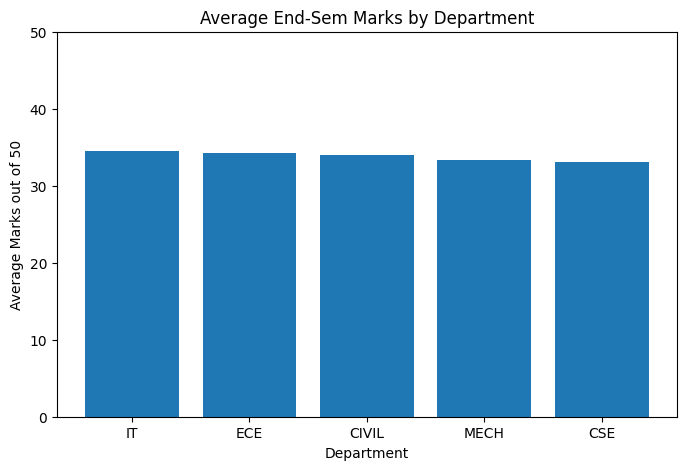

In [22]:
department_pd = department_summary.toPandas()

plt.figure(figsize=(8, 5))
plt.bar(department_pd["department"], department_pd["Avg End-Sem"])
plt.title("Average End-Sem Marks by Department")
plt.xlabel("Department")
plt.ylabel("Average Marks out of 50")
plt.ylim(0, 50)
plt.show()

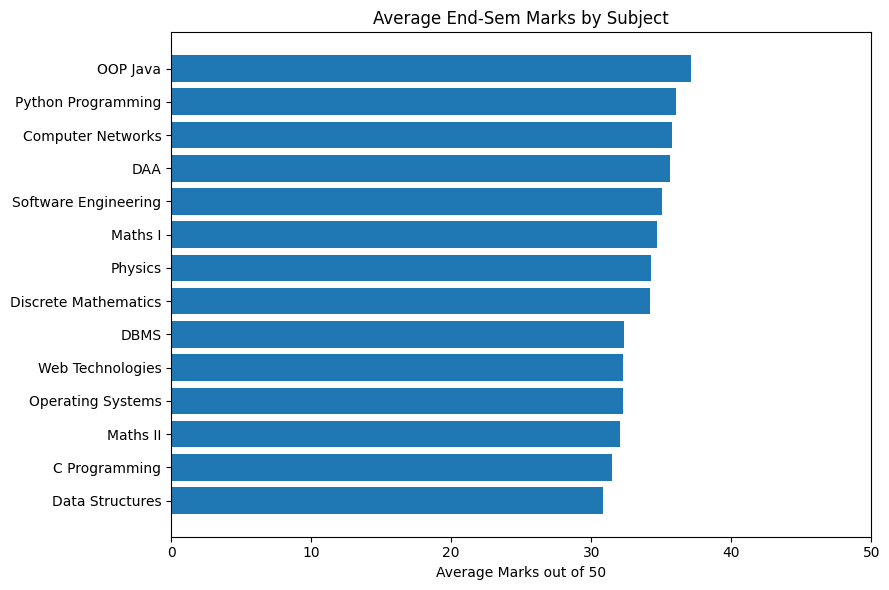

In [23]:
subject_pd = subject_summary.toPandas().sort_values("Avg End-Sem")

plt.figure(figsize=(9, 6))
plt.barh(subject_pd["subject"], subject_pd["Avg End-Sem"])
plt.title("Average End-Sem Marks by Subject")
plt.xlabel("Average Marks out of 50")
plt.xlim(0, 50)
plt.tight_layout()
plt.show()

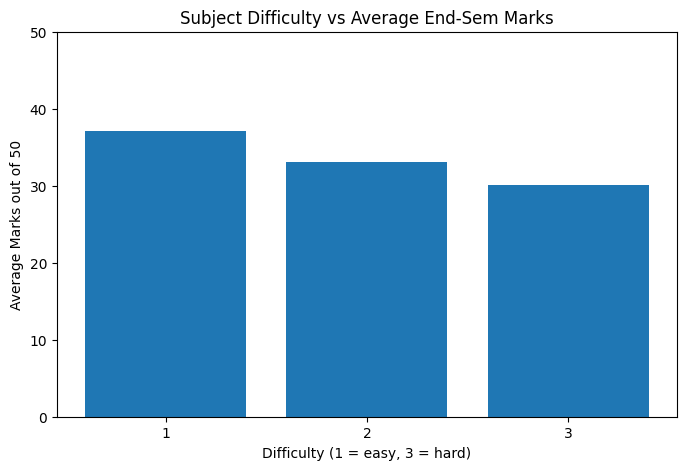

In [24]:
difficulty_pd = difficulty_summary.toPandas()

plt.figure(figsize=(8, 5))
plt.bar(difficulty_pd["difficulty"].astype(str), difficulty_pd["Avg End-Sem"])
plt.title("Subject Difficulty vs Average End-Sem Marks")
plt.xlabel("Difficulty (1 = easy, 3 = hard)")
plt.ylabel("Average Marks out of 50")
plt.ylim(0, 50)
plt.show()

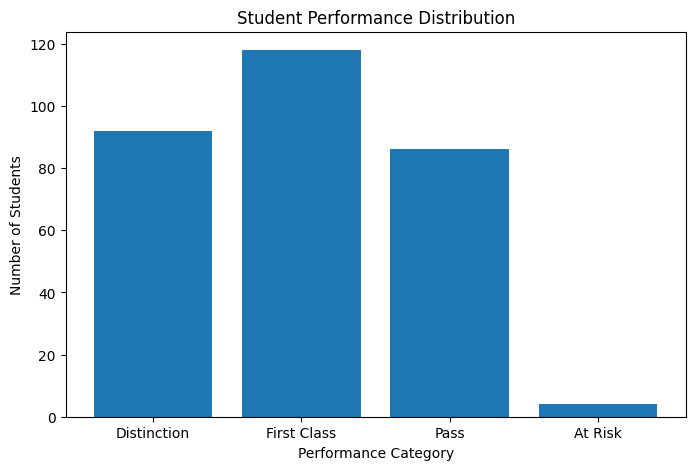

In [25]:
order = ["Distinction", "First Class", "Pass", "At Risk"]
class_pd = (df_analysis.groupBy("classification").count().toPandas()
            .set_index("classification").reindex(order).fillna(0).reset_index())

plt.figure(figsize=(8, 5))
plt.bar(class_pd["classification"], class_pd["count"])
plt.title("Student Performance Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.show()

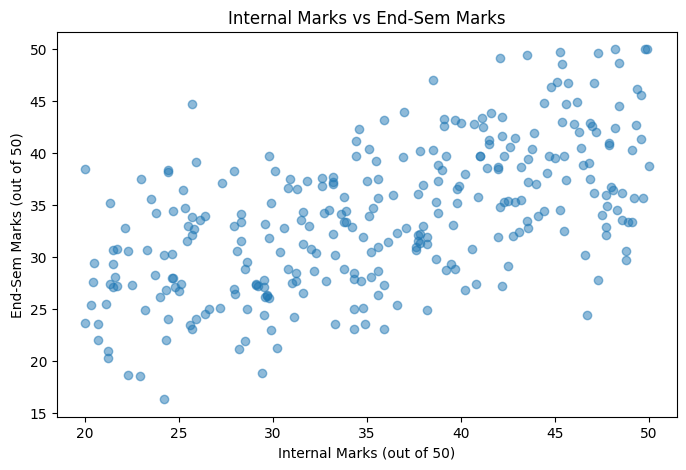

In [26]:
scores_pd = df_analysis.select("internal_marks", "end_sem_marks").toPandas()

plt.figure(figsize=(8, 5))
plt.scatter(scores_pd["internal_marks"], scores_pd["end_sem_marks"], alpha=0.5)
plt.title("Internal Marks vs End-Sem Marks")
plt.xlabel("Internal Marks (out of 50)")
plt.ylabel("End-Sem Marks (out of 50)")
plt.show()

## 6. Summary and export

In [27]:
print("STUDENT MARKS ANALYSIS USING APACHE SPARK")
print("-" * 50)

print("Total Students:", df_analysis.count())
print("Students Passed:", df_analysis.filter(F.col("result") == "Pass").count())
print("Students Failed:", df_analysis.filter(F.col("result") == "Fail").count())
print("At Risk Students:", at_risk.count())

print("\nAverage marks by department:")
department_summary.show()

print("Project analysis completed successfully!")

STUDENT MARKS ANALYSIS USING APACHE SPARK
--------------------------------------------------
Total Students: 300
Students Passed: 296
Students Failed: 4
At Risk Students: 4

Average marks by department:
+----------+------------------+------------+-----------+---------+
|department|Number of Students|Avg Internal|Avg End-Sem|Avg Total|
+----------+------------------+------------+-----------+---------+
|        IT|                63|       36.34|      34.53|    70.87|
|       ECE|                62|       35.99|      34.22|    70.21|
|     CIVIL|                76|       36.89|      34.02|    70.91|
|      MECH|                48|       33.69|       33.3|    66.98|
|       CSE|                51|       34.73|      33.07|     67.8|
+----------+------------------+------------+-----------+---------+

Project analysis completed successfully!


In [28]:
department_summary.toPandas().to_csv("department_performance.csv", index=False)
subject_summary.toPandas().to_csv("subject_performance.csv", index=False)
difficulty_summary.toPandas().to_csv("difficulty_performance.csv", index=False)
at_risk.toPandas().to_csv("students_at_risk.csv", index=False)

print("All result files saved successfully!")

All result files saved successfully!


## 7. 🔮 Prediction using Spark MLlib
**Target:** `end_sem_marks` (out of 50)

**Features removed:** `study_hrs_day` and `attendance_pct`. Change the `EXCLUDED_FEATURES` list below to add or remove features.
`student_id` is only an identifier, so it is never used.

In [29]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import RegressionEvaluator, MulticlassClassificationEvaluator, BinaryClassificationEvaluator

# ---------------- Feature configuration ----------------
EXCLUDED_FEATURES = ["study_hrs_day", "attendance_pct"]    # <- removed from prediction

ALL_CATEGORICAL = ["department", "subject"]
ALL_NUMERIC = ["year", "difficulty", "internal_marks", "attendance_pct", "study_hrs_day", "days_before_exam"]

cat_cols = [c for c in ALL_CATEGORICAL if c not in EXCLUDED_FEATURES]
num_cols = [c for c in ALL_NUMERIC if c not in EXCLUDED_FEATURES]

print("Categorical features:", cat_cols)
print("Numeric features    :", num_cols)
print("Removed features    :", EXCLUDED_FEATURES)

# Binary target: did the student score 60% or more (30+ out of 50) in the end-sem?
ml_df = df_analysis.withColumn("good_performer", (F.col("end_sem_marks") >= 30).cast("int"))

indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in cat_cols]
encoder = OneHotEncoder(inputCols=[f"{c}_idx" for c in cat_cols],
                        outputCols=[f"{c}_vec" for c in cat_cols])
assembler = VectorAssembler(inputCols=[f"{c}_vec" for c in cat_cols] + num_cols,
                            outputCol="features")

prep_stages = indexers + [encoder, assembler]

train, test = ml_df.randomSplit([0.8, 0.2], seed=42)
print("Train rows:", train.count(), "| Test rows:", test.count())

Categorical features: ['department', 'subject']
Numeric features    : ['year', 'difficulty', 'internal_marks', 'days_before_exam']
Removed features    : ['study_hrs_day', 'attendance_pct']
Train rows: 253 | Test rows: 47


### Regression: predict end-sem marks

In [30]:
reg_eval_rmse = RegressionEvaluator(labelCol="end_sem_marks", predictionCol="prediction", metricName="rmse")
reg_eval_r2   = RegressionEvaluator(labelCol="end_sem_marks", predictionCol="prediction", metricName="r2")

models = {
    "Linear Regression": LinearRegression(featuresCol="features", labelCol="end_sem_marks"),
    "Random Forest":     RandomForestRegressor(featuresCol="features", labelCol="end_sem_marks",
                                               numTrees=100, seed=42),
}

reg_models = {}
for name, algo in models.items():
    model = Pipeline(stages=prep_stages + [algo]).fit(train)
    preds = model.transform(test)
    reg_models[name] = model
    print(f"{name:20s}  RMSE = {reg_eval_rmse.evaluate(preds):6.2f}   R2 = {reg_eval_r2.evaluate(preds):5.3f}")

# Baseline for context: always predict the training mean
mean_marks = train.agg(F.avg("end_sem_marks")).first()[0]
baseline = test.withColumn("prediction", F.lit(mean_marks))
print(f"{'Baseline (mean)':20s}  RMSE = {reg_eval_rmse.evaluate(baseline):6.2f}")

Linear Regression     RMSE =   3.88   R2 = 0.650
Random Forest         RMSE =   4.22   R2 = 0.586
Baseline (mean)       RMSE =   6.56


### Which factors matter most? (Random Forest feature importance)

                       feature  importance
                internal_marks    0.477030
                    difficulty    0.185339
              days_before_exam    0.151469
                          year    0.025557
subject_vec_Python Programming    0.013917
               subject_vec_DAA    0.013549
              subject_vec_DBMS    0.013079
             department_vec_IT    0.012407
           subject_vec_Maths I    0.010617
          department_vec_CIVIL    0.010325


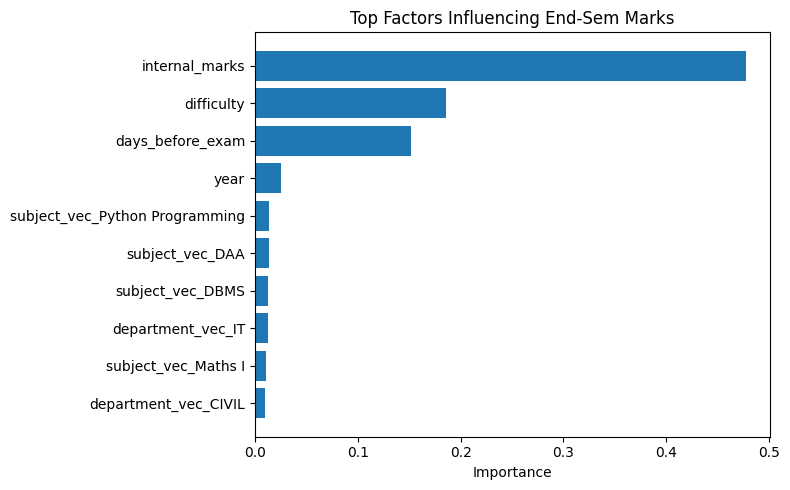

In [31]:
import pandas as pd

rf_model = reg_models["Random Forest"]
preds = rf_model.transform(test)

attrs = preds.schema["features"].metadata["ml_attr"]["attrs"]
names = [a["name"] for group in attrs.values() for a in sorted(group, key=lambda x: x["idx"])]
imp = rf_model.stages[-1].featureImportances.toArray()

importance_pd = (pd.DataFrame({"feature": names, "importance": imp})
                 .sort_values("importance", ascending=False).head(10))
print(importance_pd.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(importance_pd["feature"][::-1], importance_pd["importance"][::-1])
plt.title("Top Factors Influencing End-Sem Marks")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### Classification: predict good performer (end-sem 60% or more)

In [32]:
auc_eval = BinaryClassificationEvaluator(labelCol="good_performer", metricName="areaUnderROC")
acc_eval = MulticlassClassificationEvaluator(labelCol="good_performer", predictionCol="prediction",
                                             metricName="accuracy")
f1_eval  = MulticlassClassificationEvaluator(labelCol="good_performer", predictionCol="prediction",
                                             metricName="f1")

classifiers = {
    "Logistic Regression": LogisticRegression(featuresCol="features", labelCol="good_performer"),
    "Random Forest":       RandomForestClassifier(featuresCol="features", labelCol="good_performer",
                                                  numTrees=100, seed=42),
}

clf_models = {}
for name, algo in classifiers.items():
    model = Pipeline(stages=prep_stages + [algo]).fit(train)
    preds = model.transform(test)
    clf_models[name] = model
    print(f"{name:20s}  Accuracy = {acc_eval.evaluate(preds):.3f}   "
          f"F1 = {f1_eval.evaluate(preds):.3f}   AUC = {auc_eval.evaluate(preds):.3f}")

# Confusion matrix for Logistic Regression
best = clf_models["Logistic Regression"].transform(test)
best.groupBy("good_performer", "prediction").count().orderBy("good_performer", "prediction").show()

Logistic Regression   Accuracy = 0.809   F1 = 0.806   AUC = 0.862
Random Forest         Accuracy = 0.851   F1 = 0.838   AUC = 0.885
+--------------+----------+-----+
|good_performer|prediction|count|
+--------------+----------+-----+
|             0|       0.0|    8|
|             0|       1.0|    5|
|             1|       0.0|    4|
|             1|       1.0|   30|
+--------------+----------+-----+



### Actual vs predicted (visual for the report)

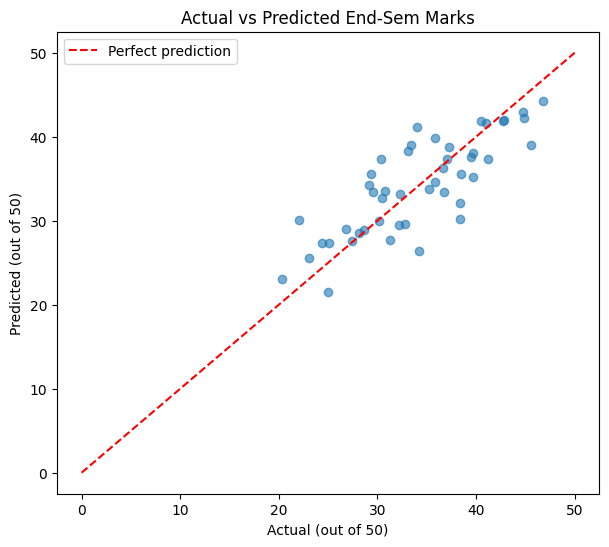

In [33]:
pred_pd = reg_models["Linear Regression"].transform(test).select("end_sem_marks", "prediction").toPandas()

plt.figure(figsize=(7, 6))
plt.scatter(pred_pd["end_sem_marks"], pred_pd["prediction"], alpha=0.6)
plt.plot([0, 50], [0, 50], "r--", label="Perfect prediction")
plt.title("Actual vs Predicted End-Sem Marks")
plt.xlabel("Actual (out of 50)")
plt.ylabel("Predicted (out of 50)")
plt.legend()
plt.show()

### Helper to predict for a single student (used by the dashboard)

In [34]:
def predict_marks(department, subject, year, difficulty, internal_marks, days_before_exam,
                  attendance_pct=75.0, study_hrs_day=4.0):
    """Predict end-sem marks (out of 50) and the chance of scoring 60%+.
    attendance_pct and study_hrs_day are accepted only for completeness; they are NOT used
    because they are listed in EXCLUDED_FEATURES."""
    row = spark.createDataFrame(
        [(department, subject, int(year), int(difficulty), float(internal_marks),
          float(attendance_pct), float(study_hrs_day), int(days_before_exam))],
        ["department", "subject", "year", "difficulty", "internal_marks",
         "attendance_pct", "study_hrs_day", "days_before_exam"]
    )
    marks = reg_models["Linear Regression"].transform(row).first()["prediction"]
    prob = clf_models["Logistic Regression"].transform(row).first()["probability"][1]
    return round(min(max(float(marks), 0.0), 50.0), 1), round(float(prob) * 100, 1)

# Example call
print(predict_marks("CSE", "DBMS", 2, 2, 38.0, 20))

(30.9, 43.9)


## 8. 📊 Gradio Dashboard

In [35]:
!pip -q install gradio plotly

In [36]:
import pandas as pd
import gradio as gr
import plotly.express as px
import plotly.graph_objects as go

# Convert Spark DataFrame to Pandas for the dashboard
data = df_analysis.toPandas()

def classify(end_sem_pct):
    if end_sem_pct >= 75:
        return "Distinction"
    elif end_sem_pct >= 60:
        return "First Class"
    elif end_sem_pct >= 40:
        return "Pass"
    else:
        return "At Risk"

print("Dataset prepared successfully!")
print("Total records:", len(data))
display(data.head())

Dataset prepared successfully!
Total records: 300


,student_id,department,year,subject,difficulty,internal_marks,attendance_pct,study_hrs_day,days_before_exam,end_sem_marks,total_marks,end_sem_pct,classification,result
0,1,MECH,3,Maths I,1,43.2,71.9,6.9,5,38.7,81.9,77.4,Distinction,Pass
1,2,IT,2,Maths II,2,43.6,56.4,3.9,55,37.2,80.8,74.4,First Class,Pass
2,3,CSE,1,Maths I,3,33.3,61.4,4.7,49,30.2,63.5,60.4,First Class,Pass
3,4,MECH,2,Data Structures,3,30.6,98.5,7.2,11,32.8,63.4,65.6,First Class,Pass
4,5,CIVIL,1,Software Engineering,2,24.6,84.2,6.1,19,30.3,54.9,60.6,First Class,Pass


In [37]:
def dashboard(department):
    df = data.copy()

    if department != "All":
        df = df[df["department"] == department]

    total_students = len(df)
    average_marks = df["end_sem_marks"].mean() if total_students else 0
    at_risk = (df["classification"] == "At Risk").sum()
    distinction = (df["classification"] == "Distinction").sum()

    metrics = f"""
    <div style="display: grid; grid-template-columns: repeat(4, minmax(0, 1fr)); gap: 16px; width: 100%; margin: 10px 0 24px 0;">
        <div style="background: #EEF2FF; border-left: 5px solid #6366F1; padding: 22px 16px; border-radius: 12px; text-align: center;">
            <div style="font-size: 15px; color: #4338CA;">Total Students</div>
            <div style="font-size: 32px; font-weight: bold; color: #312E81;">{total_students}</div>
            <div style="font-size: 12px; color: #4338CA;">Students analyzed</div>
        </div>
        <div style="background: #ECFDF5; border-left: 5px solid #10B981; padding: 22px 16px; border-radius: 12px; text-align: center;">
            <div style="font-size: 15px; color: #047857;">Average End-Sem Marks</div>
            <div style="font-size: 32px; font-weight: bold; color: #065F46;">{average_marks:.2f}</div>
            <div style="font-size: 12px; color: #047857;">Out of 50</div>
        </div>
        <div style="background: #FEF2F2; border-left: 5px solid #EF4444; padding: 22px 16px; border-radius: 12px; text-align: center;">
            <div style="font-size: 15px; color: #B91C1C;">At Risk</div>
            <div style="font-size: 32px; font-weight: bold; color: #991B1B;">{at_risk}</div>
            <div style="font-size: 12px; color: #B91C1C;">End-sem below 40%</div>
        </div>
        <div style="background: #FFFBEB; border-left: 5px solid #F59E0B; padding: 22px 16px; border-radius: 12px; text-align: center;">
            <div style="font-size: 15px; color: #B45309;">Distinction</div>
            <div style="font-size: 32px; font-weight: bold; color: #92400E;">{distinction}</div>
            <div style="font-size: 12px; color: #B45309;">End-sem 75% or above</div>
        </div>
    </div>
    """

    # Bar chart: average end-sem marks by subject
    subject_scores = (
        df.groupby("subject", as_index=False)["end_sem_marks"].mean()
        .sort_values("end_sem_marks", ascending=False)
    )
    bar_chart = px.bar(
        subject_scores, x="subject", y="end_sem_marks",
        title="Average End-Sem Marks by Subject",
        labels={"subject": "Subject", "end_sem_marks": "Average Marks (out of 50)"},
        range_y=[0, 50], text_auto=".1f"
    )
    bar_chart.update_layout(template="plotly_white", xaxis_tickangle=-35, height=420)

    # Pie chart: classification breakdown
    order = ["Distinction", "First Class", "Pass", "At Risk"]
    classification_counts = (
        df["classification"].value_counts()
        .reindex(order, fill_value=0)
        .rename_axis("Classification")
        .reset_index(name="Students")
    )
    pie_chart = px.pie(
        classification_counts, names="Classification", values="Students",
        title="Student Classification Breakdown", hole=0.45
    )
    pie_chart.update_layout(template="plotly_white", height=420)

    # Student records
    records = df[
        ["student_id", "department", "year", "subject", "difficulty",
         "internal_marks", "end_sem_marks", "total_marks", "classification"]
    ].head(20)

    return metrics, bar_chart, pie_chart, records

### Prepare prediction results for the dashboard

In [38]:
# Model comparison table
rows = []
base = test.withColumn("prediction", F.lit(mean_marks))
rows.append({"Task": "Regression", "Model": "Baseline (mean)",
             "RMSE": round(reg_eval_rmse.evaluate(base), 2), "R2": None,
             "Accuracy": None, "F1": None, "AUC": None})

for name, model in reg_models.items():
    pr = model.transform(test)
    rows.append({"Task": "Regression", "Model": name,
                 "RMSE": round(reg_eval_rmse.evaluate(pr), 2),
                 "R2": round(reg_eval_r2.evaluate(pr), 3),
                 "Accuracy": None, "F1": None, "AUC": None})

for name, model in clf_models.items():
    pr = model.transform(test)
    rows.append({"Task": "Classification (60%+)", "Model": name,
                 "RMSE": None, "R2": None,
                 "Accuracy": round(acc_eval.evaluate(pr), 3),
                 "F1": round(f1_eval.evaluate(pr), 3),
                 "AUC": round(auc_eval.evaluate(pr), 3)})

model_metrics_df = pd.DataFrame(rows)

# Feature importance chart (Random Forest regressor)
rf_model = reg_models["Random Forest"]
rf_preds = rf_model.transform(test)
attrs = rf_preds.schema["features"].metadata["ml_attr"]["attrs"]
feat_names = [a["name"] for group in attrs.values() for a in sorted(group, key=lambda x: x["idx"])]
feat_imp = rf_model.stages[-1].featureImportances.toArray()
imp_df = (pd.DataFrame({"Feature": feat_names, "Importance": feat_imp})
          .sort_values("Importance", ascending=True).tail(10))

importance_fig = px.bar(imp_df, x="Importance", y="Feature", orientation="h",
                        title="Top Factors Influencing End-Sem Marks")
importance_fig.update_layout(template="plotly_white", height=420)

# Actual vs predicted chart (Linear Regression)
ap = reg_models["Linear Regression"].transform(test).select("end_sem_marks", "prediction").toPandas()
avp_fig = px.scatter(ap, x="end_sem_marks", y="prediction", opacity=0.6,
                     title="Actual vs Predicted End-Sem Marks",
                     labels={"end_sem_marks": "Actual", "prediction": "Predicted"})
avp_fig.add_trace(go.Scatter(x=[0, 50], y=[0, 50], mode="lines", name="Perfect prediction",
                             line=dict(dash="dash", color="red")))
avp_fig.update_layout(template="plotly_white", height=420)

display(model_metrics_df)

,Task,Model,RMSE,R2,Accuracy,F1,AUC
0,Regression,Baseline (mean),6.56,NaN,NaN,NaN,NaN
1,Regression,Linear Regression,3.88,0.650,NaN,NaN,NaN
2,Regression,Random Forest,4.22,0.586,NaN,NaN,NaN
3,Classification (60%+),Logistic Regression,NaN,NaN,0.809,0.806,0.862
4,Classification (60%+),Random Forest,NaN,NaN,0.851,0.838,0.885


### Launch the dashboard

In [39]:
departments = sorted(data["department"].unique())
subjects = sorted(data["subject"].unique())

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Student Marks Analytics"
) as app:

    gr.Markdown("""
    # 🎓 Student Marks Analytics
    **Big Data Analytics using Apache Spark**

    Explore end-sem results, performance categories, and predict marks.
    """)

    with gr.Row():
        dept_filter = gr.Dropdown(
            choices=["All"] + departments,
            value="All",
            label="Filter by Department",
            scale=1
        )

    gr.Markdown("## 📊 Overview")
    metrics_output = gr.HTML()

    gr.Markdown("## 📈 Performance Analysis")
    with gr.Row():
        bar_output = gr.Plot(label="Average Marks Analysis", scale=1)
        pie_output = gr.Plot(label="Classification Analysis", scale=1)

    gr.Markdown("## 👨‍🎓 Student Records")
    records_output = gr.Dataframe(label="First 20 Student Records", interactive=False)

    gr.Markdown("## 🤖 Prediction Insights")
    gr.Markdown("Models trained with Spark MLlib to predict end-sem marks (80% train / 20% test split). "
                "Study hours and attendance are **not** used as features.")

    gr.Dataframe(value=model_metrics_df, label="Model Performance Comparison", interactive=False)

    with gr.Row():
        gr.Plot(value=importance_fig, label="Feature Importance", scale=1)
        gr.Plot(value=avp_fig, label="Actual vs Predicted", scale=1)

    gr.Markdown("## 🔮 Predict End-Sem Marks")
    gr.Markdown("Enter a student profile to predict the end-sem marks (out of 50).")

    with gr.Row():
        d_in = gr.Dropdown(departments, value=departments[0], label="Department")
        s_in = gr.Dropdown(subjects, value=subjects[0], label="Subject")
    with gr.Row():
        y_in = gr.Slider(1, 4, value=2, step=1, label="Year")
        df_in = gr.Slider(1, 3, value=2, step=1, label="Subject Difficulty (1 = easy, 3 = hard)")
    with gr.Row():
        im_in = gr.Slider(0, 50, value=35, step=0.5, label="Internal Marks (out of 50)")
        db_in = gr.Slider(0, 60, value=20, step=1, label="Days Before Exam")

    predict_btn = gr.Button("Predict", variant="primary")

    with gr.Row():
        marks_out = gr.Number(label="Predicted End-Sem Marks (out of 50)")
        prob_out = gr.Number(label="Chance of Scoring 60%+ (%)")
        label_out = gr.Textbox(label="Predicted Category")

    def predict_ui(department, subject, year, difficulty, internal_marks, days_before_exam):
        marks, prob = predict_marks(department, subject, year, difficulty, internal_marks, days_before_exam)
        return marks, prob, classify(marks * 2)

    predict_btn.click(
        fn=predict_ui,
        inputs=[d_in, s_in, y_in, df_in, im_in, db_in],
        outputs=[marks_out, prob_out, label_out]
    )

    dept_filter.change(
        fn=dashboard, inputs=[dept_filter],
        outputs=[metrics_output, bar_output, pie_output, records_output]
    )
    app.load(
        fn=dashboard, inputs=[dept_filter],
        outputs=[metrics_output, bar_output, pie_output, records_output]
    )

app.launch(share=True)

/tmp/ipykernel_3800/1363536693.py:4: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cc39eedd8b026fe555.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
